# Purpose 
This simple code allows to quickly load and process images acquired from micro-manager
Under the hood it uses pycromanager (https://github.com/micro-manager/pycro-manager) 

In [24]:
import mmpyreader
import matplotlib.cm as cm 
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc('image', cmap='gray') # set default cmap as gray
import numpy as np 

# A green colormap (for GFP)
import matplotlib
vals = np.linspace(0,1,256)
cols = vals*np.array([[0,1,0]]*256).T
cols = cols.T
gfpcmap = matplotlib.colors.ListedColormap(cols)

In [19]:
# Setup the reader (if any issue with ZMQ check that micro-manager is running and the server setup on port 4827)
# cf: 
reader = mmpyreader.MMpyreader()
# Load our hyperstack
stack = reader.load_folder("/mnt/dioscuri-nas/Ola/2022.02.02_observ/_9/",True)
#stack = reader.load_folder("/mnt/dioscuri-nas/Ola/2021.11.19_colonies2/_1",True)

2C x 5P x 44T x 9Z


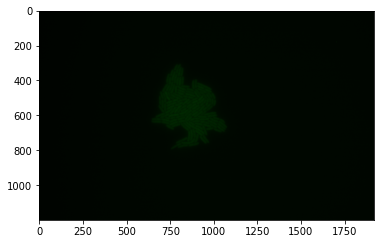

In [31]:
# Get a single image
img,img_meta = stack.get_img(C=0,P=0,T=0,Z=6)
plt.imshow(img,cmap=gfpcmap)

two channels: ['FITC-GFP', 'red filter']


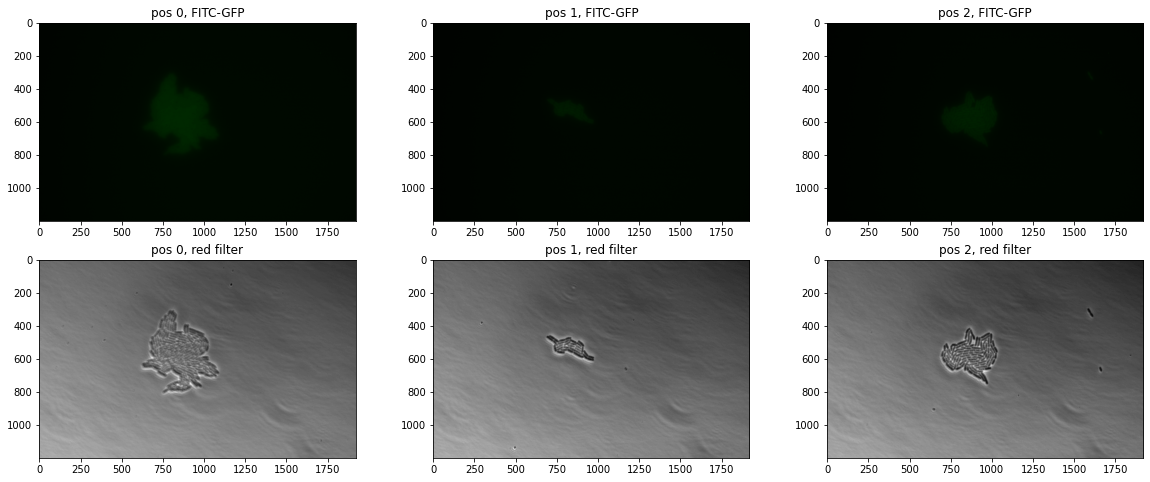

In [35]:
# Get a substack, if an element is not provided it is assumed you want 
# all elements, /!\ this is 0 indexed
# 6 elements, channel 0/1 and pos 0/1/2 
channels = [0,1]
pos = [0,1,2]
substack,substack_meta = stack.get_substack(C=channels,P=pos,T=1,Z=1)
fig,axs = plt.subplots(len(channels),len(pos),figsize=[20,8])
substack = substack.squeeze() # remove extra dims
print(f'two channels: {stack.channels}')
for i,p in enumerate(pos): 
    # Channel 0 (GFP)
    axs[0][i].imshow(substack[0][i],cmap=gfpcmap,vmax=substack[0,i].max())
    axs[0][i].set_title(f'pos {pos[i]}, {stack.channels[0]}')
    # Channel 1 bright-field
    axs[1][i].imshow(substack[1][i])
    axs[1][i].set_title(f'pos {pos[i]}, {stack.channels[1]}')


In [34]:
%%time
# this is very fast even on the NAS 
zstack,ztack_meta = stack.get_substack(C=1,P=2,T=30) # Z stack

CPU times: user 46.9 ms, sys: 45.9 ms, total: 92.9 ms
Wall time: 408 ms
